In [2]:
!nvidia-smi

Wed Oct 14 12:41:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
import tensorflow as tf

In [4]:
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [5]:
import requests
import zipfile
import io
import os

url = "https://d3ilbtxij3aepc.cloudfront.net/projects/CNN-PROJECT-7-11/Chest-Xray-2.zip"
response = requests.get(url)

with open("dataset.zip", "wb") as file:
    file.write(response.content)

In [6]:
extract_path = "/kaggle/working/chest_xray"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile("dataset.zip", "r") as zip_file:
    zip_file.extractall(extract_path)

print("Dataset extracted successfully!")
print("Dataset location:", extract_path)

for root, dirs, files in os.walk(extract_path):
    if files:
        print(f"{root}: {len(files)} files")

Dataset extracted successfully!
Dataset location: /kaggle/working/chest_xray
/kaggle/working/chest_xray/chest_xray/val: 1 files
/kaggle/working/chest_xray/chest_xray/val/NORMAL: 9 files
/kaggle/working/chest_xray/chest_xray/val/PNEUMONIA: 9 files
/kaggle/working/chest_xray/chest_xray/train: 1 files
/kaggle/working/chest_xray/chest_xray/train/NORMAL: 1342 files
/kaggle/working/chest_xray/chest_xray/train/PNEUMONIA: 3876 files
/kaggle/working/chest_xray/chest_xray/test: 1 files
/kaggle/working/chest_xray/chest_xray/test/NORMAL: 234 files
/kaggle/working/chest_xray/chest_xray/test/PNEUMONIA: 390 files


********Data Collection and Extraction********

In [7]:
DATA_DIR = "/kaggle/working/chest_xray/chest_xray"
TRAIN_DIR = os.path.join(DATA_DIR, "train")
VAL_DIR = os.path.join(DATA_DIR, "val")
TEST_DIR = os.path.join(DATA_DIR, "test")

print("Train exists:", os.path.isdir(TRAIN_DIR))
print("Validation exists:", os.path.isdir(VAL_DIR))
print("Test exists:", os.path.isdir(TEST_DIR))

Train exists: True
Validation exists: True
Test exists: True


******2.Data Preparation*******

In [8]:
#Image Configuration
IMAGE_SIZE = (224,224)
BATCH_SIZE = 32

*****2.2 Data Import*****

In [76]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size = IMAGE_SIZE,
    batch_size = BATCH_SIZE,
    shuffle = True
)

val_dataset = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size = IMAGE_SIZE,
    batch_size = BATCH_SIZE,
    shuffle = False
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size = IMAGE_SIZE,
    batch_size = BATCH_SIZE,
    shuffle = False
)

Found 5216 files belonging to 2 classes.
Found 624 files belonging to 2 classes.
Found 16 files belonging to 2 classes.


**The Test data has higher images then the validation so the test dataset will have been used as validation**

******Importing Libraries******

In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import PIL
from collections import Counter


****3.0.Exploratary Data Analysis****

In [79]:
#Data Shape
for image,label in train_dataset.take(1):
    print('The Shape of the Image:',image.shape)
    print('The Shape of Label:',label.shape)

The Shape of the Image: (32, 224, 224, 3)
The Shape of Label: (32,)


***3.1.Counting Values Per Classes***

In [80]:
#Data Counting
train_count = Counter()
test_count = Counter()
val_count = Counter()

dataset = ['Training Dataset','Testing Dataset','Validation Dataset']

def count_images(dataset,counter,class_name):

    for image,lable in dataset:
        counter.update(lable.numpy())

    print(f'\nIn {class_name}..........')

    for class_names,count in sorted(counter.items()):
        print(dataset.class_names[class_names],':',count)

    return


train_counter = count_images(train_dataset,train_count,'Training Dataset')
test_counter = count_images(test_dataset,test_count,'Testing Dataset')
val_counter = count_images(val_dataset,val_count,'Validation Dataset')




In Training Dataset..........
NORMAL : 1341
PNEUMONIA : 3875

In Testing Dataset..........
NORMAL : 8
PNEUMONIA : 8

In Validation Dataset..........
NORMAL : 234
PNEUMONIA : 390


***3.2.Calculate the Total Data Size***

In [81]:
train_total = sum(train_count.values())
test_total = sum(test_count.values())
val_total = sum(val_count.values())

total_ds = train_total+test_total+val_total

print(f'Training Images : {train_total}')
print(f'Testing Images : {test_total}')
print(f'Validation Images : {val_total}')

print(f'\nTotal Images in All dataset:{total_ds}')

Training Images : 5216
Testing Images : 16
Validation Images : 624

Total Images in All dataset:5856


***3.3.Class Distrubution***

In [82]:
class_df = pd.DataFrame({
    'class':train_count.keys(),
    'image count':train_count.values()
})

class_df['class'] = class_df['class'].map({0:'NORMAL',1:'PNEUMONIA'})

class_df['percentage'] = round(
    class_df['image count']/class_df['image count'].sum()*100
    )

class_df = class_df.sort_values('class').reset_index(drop=True)

class_df



,class,image count,percentage
0,NORMAL,1341,26.0
1,PNEUMONIA,3875,74.0


***3.4.Visualizing Class Distrubution***

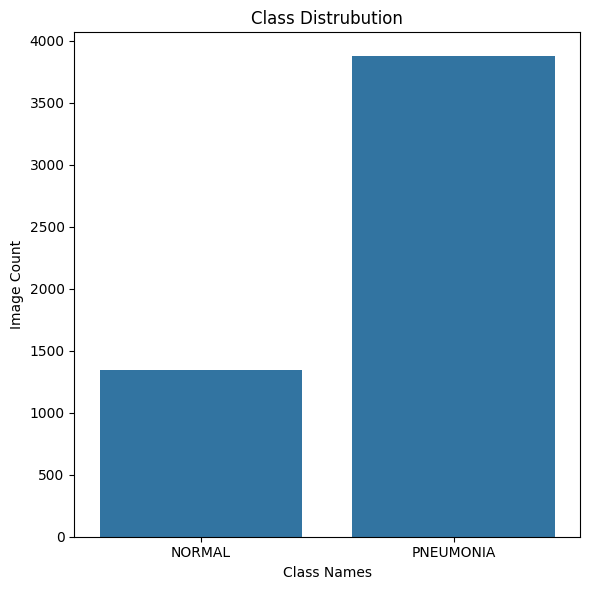

In [83]:
plt.figure(figsize=(6,6))

sns.barplot(
    data=class_df,
    x='class',
    y='image count'
)


plt.xlabel('Class Names')
plt.ylabel('Image Count')
plt.title('Class Distrubution')
plt.tight_layout()
plt.show()


*The Dataset is Imbalance*

***3.5.Class across three Dataset***

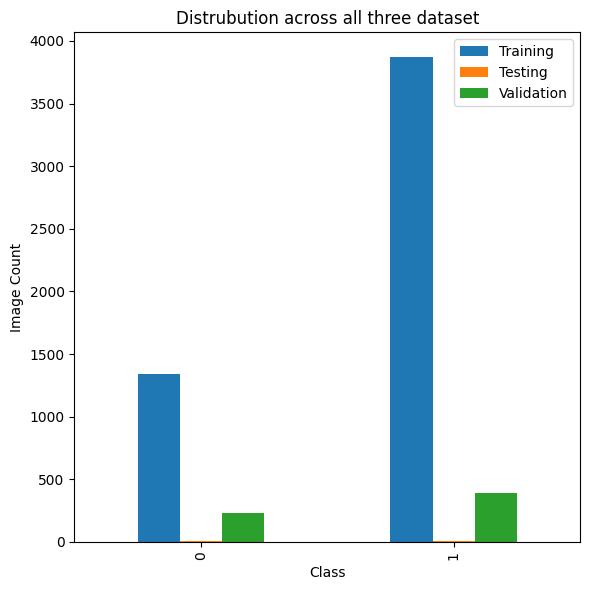

In [84]:
distrubution_df = pd.DataFrame({
    'Training':pd.Series(train_count),
    'Testing':pd.Series(test_count),
    'Validation':pd.Series(val_count)
})


distrubution_df.plot(
    kind='bar',
    figsize=(6,6)
)

plt.title('Distrubution across all three dataset')
plt.xlabel('Class')
plt.ylabel('Image Count')
plt.tight_layout()
plt.show()

***3.6.Visualizing Sample X Ray Images***

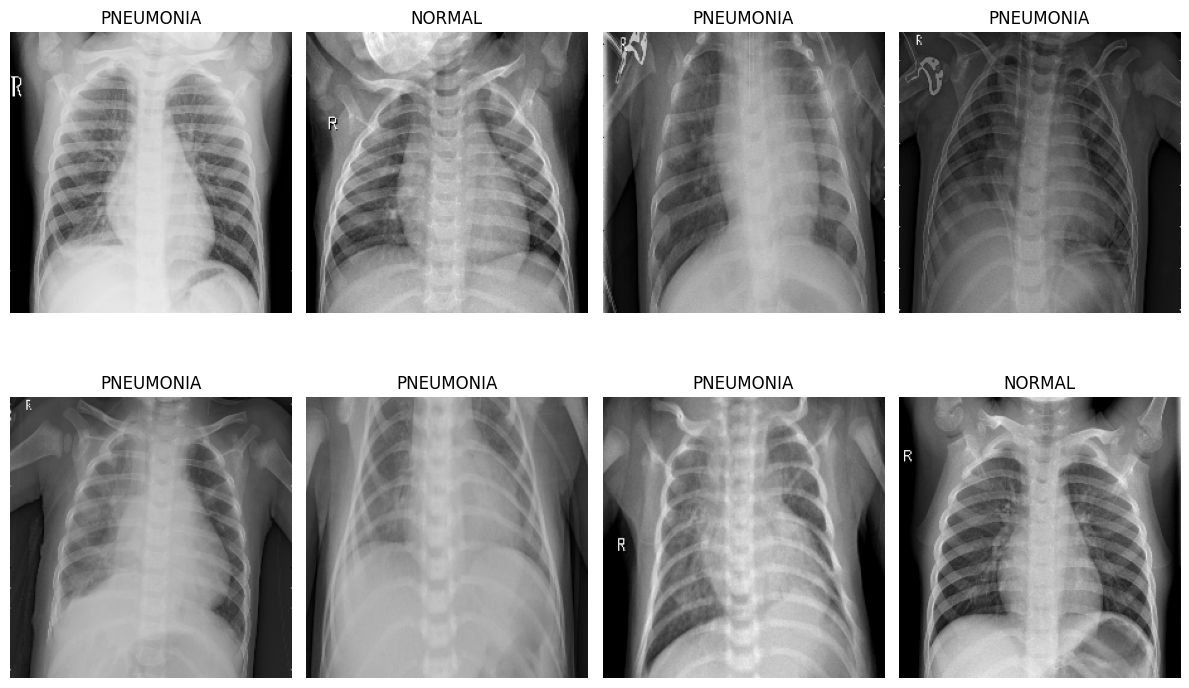

In [136]:
class_names = train_dataset.class_names

for image,label in train_dataset.take(1):

    plt.figure(figsize=(12,8))

    for i in range(8):
        plt.subplot(2,4,i+1)
        plt.imshow(image[i].numpy().astype('uint8'),cmap='grey')
        plt.title(class_names[label[i].numpy()])
        plt.axis('off')

    plt.tight_layout()
    plt.show()


****4.0.Data Preprocessing****

***4.1.Handling Imbalance Dataset***

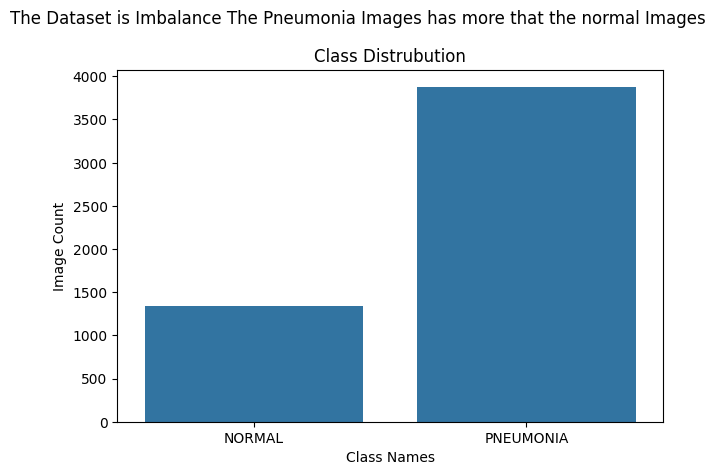

In [86]:
sns.barplot(
    data=class_df,
    x='class',
    y='image count'
)

plt.xlabel('Class Names')
plt.ylabel('Image Count')
plt.title('Class Distrubution')
plt.suptitle('The Dataset is Imbalance The Pneumonia Images has more that the normal Images',fontsize = 12)
plt.tight_layout()
plt.show()

*The dataset is imbalanced. The pneumonia images are more numerous than the normal images. So, we are going to use oversampling techniques with data augmentation, and we are going to increase the number of normal images upto 2,000.*

****4.2.Oversampling****

**4.2.1.Seperate dataset by classes**

In [87]:
normal_ds = train_dataset.unbatch().filter(
    lambda image,label : tf.equal(label,0 )
)

**4.2.2.Data Augementation**

In [89]:
data_augmentation_oversampling = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.3),
    tf.keras.layers.RandomTranslation(
        height_factor = 0.3,
        width_factor = 0.3,
    ),
    tf.keras.layers.RandomZoom(0.3)
]
)

***4.2.3.Producing New 700 Images***

In [90]:
normal_augmented = (
    normal_ds
    .repeat()
    .take(700)
    .map(
        lambda image,label:(
            data_augmentation_oversampling(image,training = True),label),
        num_parallel_calls = 1
    )
)

**4.2.4.Adding To the Dataset***

In [92]:
balanced_training_ds = (
    train_dataset
    .unbatch()
    .concatenate(normal_augmented)
    .shuffle(
        buffer_size=256,
        seed=43,
        reshuffle_each_iteration=True
    )
    .batch(BATCH_SIZE)
    .prefetch(1)
)

In [93]:
for images, labels in balanced_training_ds.take(1):
    print("Image shape:", images.shape)
    print("Labels:", labels.numpy())
    print("Unique labels:", tf.unique(labels).y.numpy())

Image shape: (32, 224, 224, 3)
Labels: [1 0 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 0 1 0 1 1 1 1 1 1 0 1 1 1 0]
Unique labels: [1 0]


***4.3.After Oversampling***

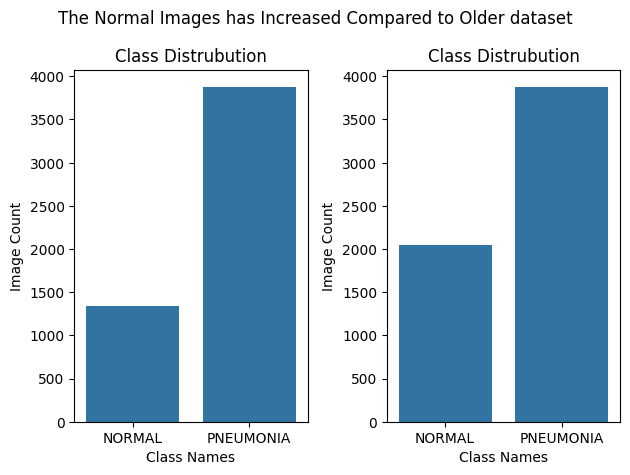

In [94]:
balanced_training_count = {
    0 : train_count[0]+700,
    1 : train_count[1]
}

balanced_training_df = pd.DataFrame({
    'class':balanced_training_count.keys(),
    'image_count':balanced_training_count.values()
})

balanced_training_df['class'] = balanced_training_df['class'].map({0:'NORMAL',1:'PNEUMONIA'})


plt.subplot(1,2,1)
sns.barplot(
    data=class_df,
    x='class',
    y='image count'
)

plt.xlabel('Class Names')
plt.ylabel('Image Count')
plt.title('Class Distrubution')

plt.tight_layout()


plt.subplot(1,2,2)
sns.barplot(
    data=balanced_training_df,
    x='class',
    y='image_count'
)


plt.xlabel('Class Names')
plt.ylabel('Image Count')
plt.title('Class Distrubution')
plt.suptitle('The Normal Images has Increased Compared to Older dataset',fontsize = 12)
plt.tight_layout()
plt.show()




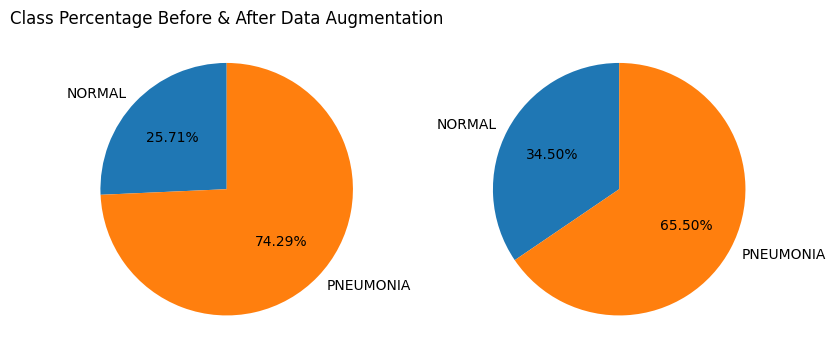

In [95]:
plt.figure(figsize=(8,8))
plt.subplot(1,2,1)
plt.title('Class Percentage Before & After Data Augmentation')


plt.pie(
    class_df['image count'],
    labels = class_df['class'],
    autopct='%1.2f%%',
    startangle=90
)


plt.subplot(1,2,2)
plt.pie(
    balanced_training_df['image_count'],
    labels=balanced_training_df['class'],
    autopct='%1.2f%%',
    startangle=90
)

plt.tight_layout()
plt.show()


*The Normal Images Incresed to 2000 or above*

***4.3.Data Scaling***

In [96]:
scaled_train_ds = balanced_training_ds.map(lambda x,y:(x/255.0,y))

scaled_iter = scaled_train_ds.as_numpy_iterator()
batch = scaled_iter.next()
print(batch[0].min())
print(batch[0].max())

0.0
1.0


**4.4.Setting Batches**

In [97]:
print("Normal Data Cardinality:", tf.data.experimental.cardinality(
    balanced_training_ds
).numpy())


Cardinality: -2


The Cardinality shows -2 which means it has unknown number of batches so we have to apply approriate batch size to dataset

In [116]:
print("Cardinality:", tf.data.experimental.cardinality(
    scaled_train_ds
).numpy())

Scaled Data Cardinality: -2


In [117]:
batch_count = 0
image_count = 0

for images, labels in balanced_training_ds:
    batch_count += 1
    image_count += images.shape[0]

print("Total images:", image_count)
print("Total batches:", batch_count)

Total images: 5916
Total batches: 185


The Batch size is 185 which came from dividing total image by 32 (****5916/32****) we should set 185 as cardinality value



In [120]:
balanced_training_ds = balanced_training_ds.apply(tf.data.experimental.assert_cardinality(185))

scaled_train_ds = scaled_train_ds.apply(tf.data.experimental.assert_cardinality(185))

In [145]:
print('Normal Dataset cardinality:',tf.data.experimental.cardinality(
    balanced_training_ds
).numpy())

print("Scaled Dataset Cardinality:", tf.data.experimental.cardinality(
    scaled_train_ds
).numpy())

Normal Dataset cardinality: 185
Scaled Dataset Cardinality: 185


***We are using Transfer Learning algorithm we no need to use scaled dataset**

In [32]:
for images, labels in balanced_training_ds.take(1):
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Minimum pixel value: 0.0
Maximum pixel value: 255.0


**5.0.Training on CNN**

**Data augmentation is not required for the training dataset, as it may alter the original X-ray images and potentially affect important medical features.**

***5.1.Define Transfer Learning***


In [103]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input,GlobalAveragePooling2D,Dense,Dropout
from tensorflow.keras.applications import EfficientNetB0

In [104]:
base_model = EfficientNetB0(
    weights='imagenet',
    include_top = False,
    input_shape = (224,224,3)
)

base_model.trainable = False

***5.2.Build a CNN Model Using Transfer Learning***

In [105]:
num_clases = len(train_dataset.class_names)

model = Sequential([
    Input(shape = (224,224,3)),

    base_model,

    GlobalAveragePooling2D(),

    Dense(128,activation = 'relu'),

    Dropout(0.3),

    Dense(num_clases,activation = 'softmax')

])

model.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,797 (16.07 MB)

 Trainable params: 164,226 (641.51 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [106]:
model.compile(
    optimizer = tf.keras.optimizers.Adam(learning_rate = 0.001),
    loss = tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics = ['accuracy']
)

In [107]:
earlystopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience = 3,restore_best_weights = True )

In [108]:
hist = model.fit(
    balanced_training_ds,
    validation_data = val_dataset,
    epochs = 15,
    callbacks = [earlystopping]
)

Epoch 1/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 75s 292ms/step - accuracy: 0.9268 - loss: 0.1758 - val_accuracy: 0.7821 - val_loss: 0.5916
Epoch 2/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 34s 180ms/step - accuracy: 0.9476 - loss: 0.1300 - val_accuracy: 0.8574 - val_loss: 0.3732
Epoch 3/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 34s 178ms/step - accuracy: 0.9616 - loss: 0.0998 - val_accuracy: 0.8766 - val_loss: 0.2763
Epoch 4/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 34s 177ms/step - accuracy: 0.9687 - loss: 0.0825 - val_accuracy: 0.8686 - val_loss: 0.3313
Epoch 5/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 33s 177ms/step - accuracy: 0.9709 - loss: 0.0796 - val_accuracy: 0.8990 - val_loss: 0.2364
Epoch 6/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 34s 177ms/step - accuracy: 0.9652 - loss: 0.0825 - val_accuracy: 0.8397 - val_loss: 0.4622
Epoch 7/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 34s 178ms/step - accuracy: 0.9713 - loss: 0.0718 - val_accuracy: 0.8526 - val_loss: 0.4229
Epoch 8/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 33s 176ms/step - accuracy: 0.9753 - loss: 0

In [109]:
hist.history


{'accuracy': [0.9268086552619934,
  0.9475997090339661,
  0.9616294503211975,
  0.9687288999557495,
  0.9709262847900391,
  0.9651791453361511,
  0.9712643623352051,
  0.9753211736679077],
 'loss': [0.17576691508293152,
  0.1300021857023239,
  0.09982827305793762,
  0.08248916268348694,
  0.07961083203554153,
  0.08249978721141815,
  0.07180706411600113,
  0.06564421206712723],
 'val_accuracy': [0.7820512652397156,
  0.8573718070983887,
  0.8766025900840759,
  0.8685897588729858,
  0.8990384340286255,
  0.8397436141967773,
  0.8525640964508057,
  0.8525640964508057],
 'val_loss': [0.5916222929954529,
  0.37324514985084534,
  0.276316374540329,
  0.3312781751155853,
  0.23640678822994232,
  0.4621540904045105,
  0.4228578209877014,
  0.4347681999206543]}

**5.4.New CNN by Manual**

In [112]:
model_2 = Sequential([

    tf.keras.layers.Input(shape=(224,224,3)),


    #Block 1
    tf.keras.layers.Conv2D(32,(3,3),activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    #Block 2
    tf.keras.layers.Conv2D(64,(3,3),activation=('relu')),
    tf.keras.layers.MaxPooling2D(),

    #Block 3
    tf.keras.layers.Conv2D(128,(3,3),activation=('relu')),
    tf.keras.layers.MaxPooling2D(),


    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128,activation='relu'),

    tf.keras.layers.Dense(num_clases,activation='softmax')
])

model_2.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,218 (42.61 MB)

 Trainable params: 11,169,218 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [113]:
model_2.compile(
    optimizer = 'adam',
    loss = tf.losses.sparse_categorical_crossentropy,
    metrics =['accuracy']
)

In [121]:
hist_2 = model_2.fit(
    scaled_train_ds,
    validation_data = val_dataset,
    epochs = 15,
    callbacks = [earlystopping]
)

Epoch 1/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 37s 193ms/step - accuracy: 0.9498 - loss: 0.1392 - val_accuracy: 0.7804 - val_loss: 164.5311
Epoch 2/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 34s 179ms/step - accuracy: 0.9525 - loss: 0.1269 - val_accuracy: 0.5785 - val_loss: 362.3508
Epoch 3/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 34s 180ms/step - accuracy: 0.9618 - loss: 0.1061 - val_accuracy: 0.8125 - val_loss: 101.6914


In [122]:
hist_2.history

{'accuracy': [0.9497971534729004, 0.9525017142295837, 0.9617984890937805],
 'loss': [0.1392308622598648, 0.12693101167678833, 0.10611972212791443],
 'val_accuracy': [0.7804487347602844, 0.5785256624221802, 0.8125],
 'val_loss': [164.53114318847656, 362.3507995605469, 101.69137573242188]}

**6.Plot Performence** **bold text**

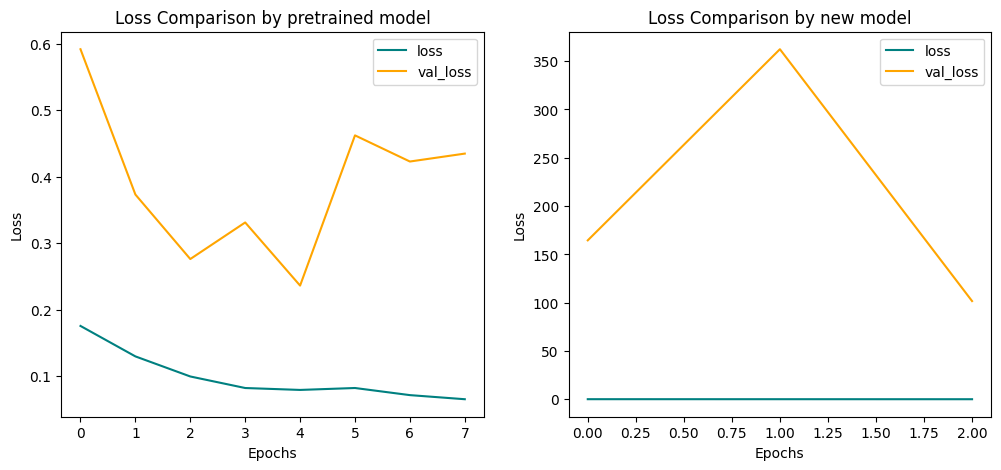

In [123]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(hist.history['loss'],color = 'teal',label = 'loss')
plt.plot(hist.history['val_loss'],color = 'orange',label = 'val_loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Loss Comparison by pretrained model')
plt.legend()

plt.subplot(1,2,2)
plt.plot(hist_2.history['loss'],color = 'teal',label = 'loss')
plt.plot(hist_2.history['val_loss'],color = 'orange',label = 'val_loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Loss Comparison by new model')
plt.legend()
plt.show()

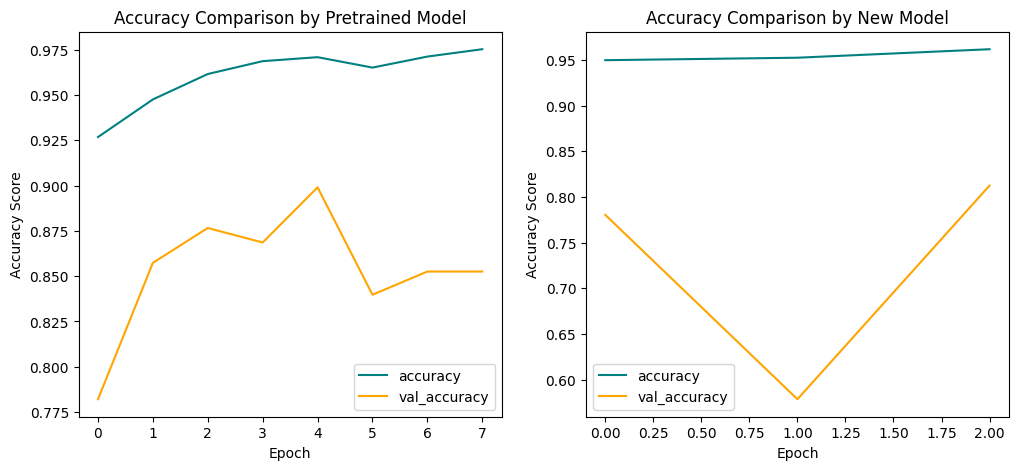

In [124]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(hist.history['accuracy'],color = 'teal',label = 'accuracy')
plt.plot(hist.history['val_accuracy'],color = 'orange',label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy Score')
plt.title('Accuracy Comparison by Pretrained Model')
plt.legend()

plt.subplot(1,2,2)
plt.plot(hist_2.history['accuracy'],color = 'teal',label = 'accuracy')
plt.plot(hist_2.history['val_accuracy'],color = 'orange',label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy Score')
plt.title('Accuracy Comparison by New Model')
plt.legend()
plt.show()

**After comparing both models, the pretrained model performed better. Therefore, we will use the pretrained model for predictions.**

**7.Evalution**

In [125]:
from tensorflow.keras.metrics import BinaryAccuracy, Recall, Precision

***7.1Confusion Matrix***

In [126]:
y_true =[]
y_pred = []


for X,y in test_dataset.as_numpy_iterator():
    pred = model.predict(X,verbose=0)
    pred_clas = np.argmax(pred,axis=1)

    y_true.extend(y)
    y_pred.extend(pred_clas)


y_true = np.array(y_true)
y_pred = np.array(y_pred)

In [127]:
from sklearn.metrics import classification_report,confusion_matrix

print(classification_report(y_true,y_pred,target_names=class_names))

              precision    recall  f1-score   support

      NORMAL       0.89      1.00      0.94         8
   PNEUMONIA       1.00      0.88      0.93         8

    accuracy                           0.94        16
   macro avg       0.94      0.94      0.94        16
weighted avg       0.94      0.94      0.94        16



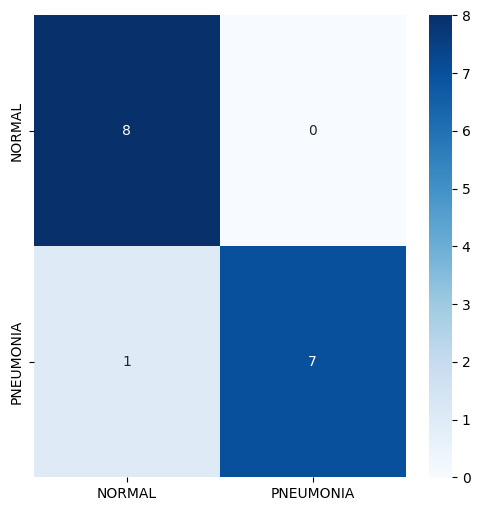

In [128]:
cm = confusion_matrix(y_true,y_pred)

plt.figure(figsize=(6,6))

sns.heatmap(cm,fmt='d',annot=True,cmap='Blues',xticklabels=class_names,yticklabels=class_names)

plt.show()

**8.Prediction System**

In [140]:
import cv2

def prediction_system(image_path):
    img = cv2.imread(image_path)

    if img is None:
        print('Image_Not_found')
        return

    img_rgb = cv2.cvtColor(img,cv2.COLOR_BGR2RGB)

    img_resized = cv2.resize(img_rgb,(224,224))

    img_batch = np.expand_dims(img_resized,axis=0)

    prediction = model.predict(img_batch,verbose=0)

    pred_index =np.argmax(prediction[0])

    
    confidence = prediction[0][pred_index]* 100

    class_name = class_names[pred_index]

    plt.figure(figsize=(5,5))
    plt.imshow(img_rgb)
    plt.title(f'Prediction :{class_name}\n'f'Confidence :{confidence:.2f}%')

    plt.axis('off')
    plt.show()

    return

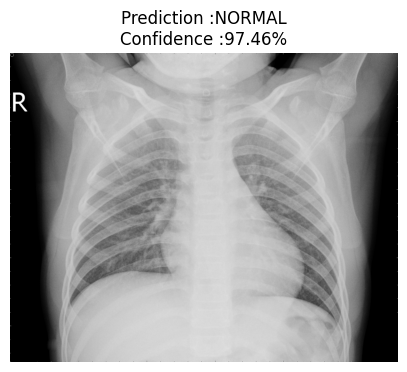

In [141]:
prediction_system('/kaggle/working/chest_xray/chest_xray/val/NORMAL/NORMAL2-IM-1427-0001.jpeg')

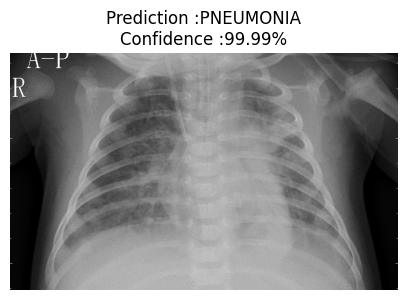

In [142]:
prediction_system('/kaggle/working/chest_xray/chest_xray/val/PNEUMONIA/person1946_bacteria_4874.jpeg')